# Validating a credit scoring model on imbalanced data

This notebook walks through a full validation of a probability-of-default (PD) model with the `scoreval` package. It follows the methodology from

> A. Tkatchev, I. Kogoleva. *Beyond Standard Metrics: Comprehensive Validation of Credit Scoring Models.* Bankovsky Vestnik, No. 8 (757), August 2026, pp. 42–52.

The questions a validator has to answer:

1. **Does ROC-AUC tell the truth?** With ~2% defaults it can look good while the model misses most defaults.
2. **Can the PDs be trusted as probabilities**, or only as a ranking?
3. **Which model-risk class** does the model fall into, and what is it allowed to be used for?
4. **How should the cut-off be set**: on PD, or as a fixed share of the riskiest applications?

All data here is **synthetic** (see `scoreval.data`): 50,000 simulated loans with a 2.1% default rate, mirroring the sample size and default rate used in the article.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..") / "src"))  # not needed after `pip install -e .`

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, roc_curve

import scoreval as sv
from scoreval.data import FEATURES, make_credit_portfolio

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
IMG = Path("..") / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)

## 1. Data

Three samples: a development sample (40,000 loans) to fit the model, an out-of-sample test set (10,000) for validation, and a later **monitoring** sample whose applicant mix has drifted (higher leverage, more credit inquiries, thinner credit files).

In [2]:
dev = make_credit_portfolio(40_000, seed=1)
test = make_credit_portfolio(10_000, seed=2)
monitoring = make_credit_portfolio(10_000, drift=0.35, seed=3)

pd.DataFrame(
    {
        "loans": [len(dev), len(test), len(monitoring)],
        "defaults": [dev["default"].sum(), test["default"].sum(), monitoring["default"].sum()],
        "bad rate": [dev["default"].mean(), test["default"].mean(), monitoring["default"].mean()],
    },
    index=["development", "test", "monitoring"],
)

,loans,defaults,bad rate
development,40000,830,0.021
test,10000,199,0.020
monitoring,10000,357,0.036


## 2. Champion model

A logistic regression on log-transformed features — a simple stand-in for a classic scorecard. The validation steps below do not depend on how the model was built: they only need outcomes and predicted PDs.

In [3]:
def X(df):
    return np.log1p(df[FEATURES])

champion = LogisticRegression(max_iter=3000).fit(X(dev), dev["default"])
pd_dev = champion.predict_proba(X(dev))[:, 1]
pd_test = champion.predict_proba(X(test))[:, 1]
pd_mon = champion.predict_proba(X(monitoring))[:, 1]
y_test = test["default"].to_numpy()

## 3. Why ROC-AUC flatters a model on rare events

The article's illustration: 1,000 borrowers, 10 of them default. The false-positive rate divides by ~990 good borrowers, so dozens of false alarms barely move it, and the ROC curve hugs the top-left corner even when most defaults are missed. Precision divides only by the loans *flagged* as bad, so every false alarm and every missed default costs PR-AUC directly.

A random model scores ROC-AUC = 0.5 but PR-AUC = the bad rate. **PR-AUC must therefore always be read as a multiple of the bad rate (the "lift").**

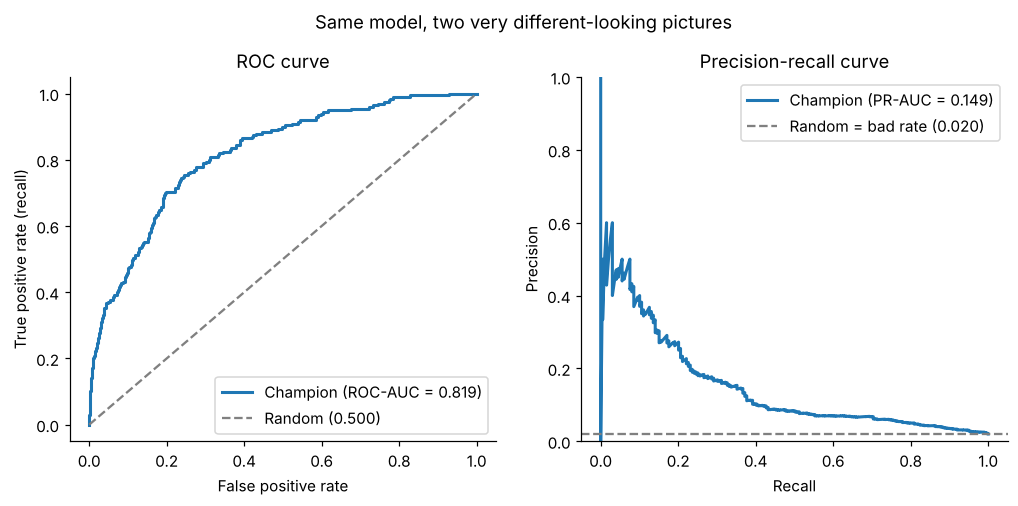

In [4]:
fpr, tpr, _ = roc_curve(y_test, pd_test)
prec, rec, _ = precision_recall_curve(y_test, pd_test)
base = sv.bad_rate(y_test)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ax[0].plot(fpr, tpr, lw=2, label=f"Champion (ROC-AUC = {sv.roc_auc(y_test, pd_test):.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="grey", label="Random (0.500)")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve")
ax[0].legend(loc="lower right")
ax[1].plot(rec, prec, lw=2, label=f"Champion (PR-AUC = {sv.pr_auc(y_test, pd_test):.3f})")
ax[1].axhline(base, ls="--", color="grey", label=f"Random = bad rate ({base:.3f})")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve", ylim=(0, 1))
ax[1].legend(loc="upper right")
fig.suptitle("Same model, two very different-looking pictures", y=1.02)
fig.savefig(IMG / "roc_vs_pr.png", bbox_inches="tight")

In [5]:
rows = []
for name, fn in [("ROC-AUC", sv.roc_auc), ("Gini", sv.gini), ("KS", sv.ks_statistic), ("PR-AUC", sv.pr_auc)]:
    est, lo, hi = sv.bootstrap_ci(fn, y_test, pd_test, n_boot=300)
    rows.append({"metric": name, "estimate": est, "95% CI low": lo, "95% CI high": hi})
rows.append({"metric": "PR-AUC lift (x bad rate)", "estimate": sv.pr_auc_lift(y_test, pd_test)})
rows.append({"metric": "Capture rate, top 10%", "estimate": sv.capture_rate(y_test, pd_test, 0.10)})
rows.append({"metric": "Capture rate, top 20%", "estimate": sv.capture_rate(y_test, pd_test, 0.20)})
pd.DataFrame(rows).set_index("metric")

,estimate,95% CI low,95% CI high
metric,,,
ROC-AUC,0.819,0.794,0.848
Gini,0.637,0.587,0.697
KS,0.508,0.465,0.575
PR-AUC,0.149,0.113,0.204
PR-AUC lift (x bad rate),7.478,NaN,NaN
"Capture rate, top 10%",0.437,NaN,NaN
"Capture rate, top 20%",0.673,NaN,NaN


With only ~200 defaults in the test set, the bootstrap intervals are wide — worth reporting alongside any point estimate. The lift of PR-AUC over the bad rate is what goes into the classification below (Table 2 of the article: < 2× very weak, 2–3× weak, 3–5× acceptable, 5–10× good, > 10× excellent).

## 4. Calibration: can the PDs be used as probabilities?

A model can rank well and still produce PDs that are systematically too high or too low. The PD-based cut-off, expected loss and IRB capital all need calibrated PDs, so calibration is checked separately:

* **Calibration slope** — logistic regression of the outcome on logit(PD); 1.0 is perfect, < 1 means PDs are too extreme, > 1 too flat.
* **ECE** — population-weighted average gap between predicted and observed default rates across PD deciles.
* **Brier score** against the naive forecast that gives everyone the average bad rate.
* **Observed / expected defaults** over the whole sample (calibration-in-the-large) — the slope cannot see a uniform shift of all PDs.
* **Hosmer–Lemeshow** and **binomial tests by grade** — the classic statistical back-tests.

Calibration slope: 0.978
ECE:               0.0036
Brier score:       0.0182  (naive 0.0195)
Observed/expected: 199 / 200 = 0.99 (p = 0.97)
Hosmer-Lemeshow:   {'statistic': 11.308, 'dof': 8, 'p_value': 0.185}


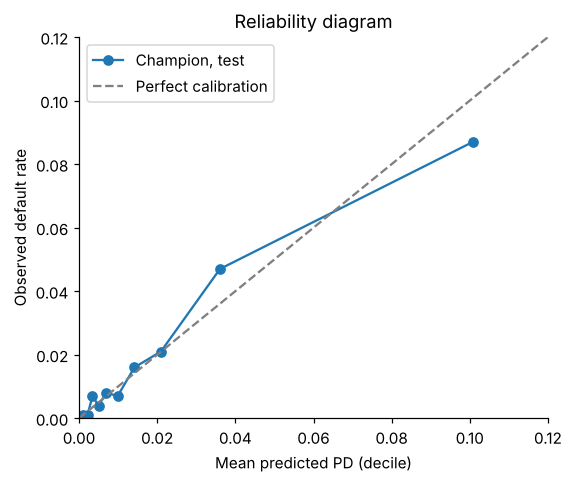

In [6]:
def reliability(ax, y, p, label, bins=10):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, bins + 1)))
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, len(edges) - 2)
    pred = [p[idx == b].mean() for b in range(len(edges) - 1)]
    obs = [y[idx == b].mean() for b in range(len(edges) - 1)]
    ax.plot(pred, obs, "o-", label=label)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
reliability(ax, y_test, pd_test, "Champion, test")
lim = 0.12
ax.plot([0, lim], [0, lim], "--", color="grey", label="Perfect calibration")
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Mean predicted PD (decile)", ylabel="Observed default rate", title="Reliability diagram")
ax.legend()
fig.savefig(IMG / "reliability.png", bbox_inches="tight")

print(f"Calibration slope: {sv.calibration_slope(y_test, pd_test):.3f}")
print(f"ECE:               {sv.expected_calibration_error(y_test, pd_test):.4f}")
print(f"Brier score:       {sv.brier_score(y_test, pd_test):.4f}  (naive {base * (1 - base):.4f})")
citl = sv.calibration_in_the_large(y_test, pd_test)
print(f"Observed/expected: {citl['observed']} / {citl['expected']:.0f} = {citl['oe_ratio']:.2f} (p = {citl['p_value']:.2f})")
print("Hosmer-Lemeshow:  ", {k: round(v, 3) for k, v in sv.hosmer_lemeshow(y_test, pd_test).items()})

In [7]:
grades = pd.qcut(pd_test, 5, labels=["G1 (safest)", "G2", "G3", "G4", "G5 (riskiest)"])
pd.DataFrame(sv.metrics.binomial_test_by_grade(y_test, pd_test, grades)).set_index("grade")

,n,defaults,observed_dr,mean_pd,p_value
grade,,,,,
G1 (safest),2000,2,0.001,0.002,0.830
G2,2000,11,0.005,0.004,0.226
G3,2000,15,0.007,0.008,0.708
G4,2000,37,0.018,0.018,0.397
G5 (riskiest),2000,134,0.067,0.068,0.613


No grade shows significantly more defaults than its mean PD predicts (all p-values well above 5%).

## 5. Two-step model-risk classification

**Step 1 — veto factors.** Any one of these rejects the model regardless of everything else:

| Criterion | Veto if |
|---|---|
| PR-AUC lift | < 2× bad rate |
| Calibration slope | < 0.3 or > 2.0 |
| PSI (development vs. current) | > 0.50 |
| Capture rate in the riskiest 10% | < 15% |

**Step 2 — penalties.** ECE, Brier vs. naive, capture rate in the top 20%, PSI and calibration slope are each scored green / yellow / red. Lift, vetoes and penalty counts then map the model to a class:

| Class | Verdict | Allowed use |
|---|---|---|
| A | Approved, full trust | Automatic PD-based cut-off, IRB, economic capital |
| B | Approved with limitations | PD-based cut-off with quarterly monitoring |
| C | Conditionally approved | Quantile cut-off only; PDs not used; recalibration plan |
| D | Weak, temporary use | Expert support only, limited lifetime |
| E | Rejected | Not allowed in production |

In [8]:
verdict = sv.validate(y_test, pd_test, reference_pd=pd_dev)
print(verdict.summary())

Class A: Approved, full trust
  PR-AUC 0.149 = 7.48x baseline (Good); ROC-AUC 0.819
  Vetoes: none
  Penalties: 0 yellow, 0 red
  Observed/expected defaults: 0.99 (p = 0.972)
  Why: all class A conditions met
  Allowed use: Automatic PD-based cut-off; suitable for IRB use and economic capital.


## 6. What the classification catches that ROC-AUC does not

Six situations a validator meets in practice. In three of them the PDs are distorted by a monotone transformation — the **ranking is identical, so ROC-AUC and PR-AUC do not move at all**, yet the PDs are no longer usable for a PD-based cut-off:

* **Overconfident PDs** — log-odds stretched 1.6×, as after over-fitting.
* **Understated risk** — log-odds shifted down by 0.7: every PD is roughly halved.
* **Champion on drifted applicants** — the monitoring sample.
* **Gradient boosting**, raw and after isotonic calibration — the extension to ML models proposed at the end of the article.

In [9]:
def distort(p, stretch=1.0, shift=0.0):
    logit = np.log(p / (1 - p))
    centre = np.log(base / (1 - base))
    return 1 / (1 + np.exp(-(stretch * (logit - centre) + centre + shift)))

gbm = HistGradientBoostingClassifier(max_iter=600, learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=5, random_state=0)
gbm.fit(dev[FEATURES], dev["default"])
gbm_dev = gbm.predict_proba(dev[FEATURES])[:, 1]
gbm_test = gbm.predict_proba(test[FEATURES])[:, 1]

# Isotonic calibration fitted on a separate calibration sample, never on the test set
calib = make_credit_portfolio(10_000, seed=4)
iso = IsotonicRegression(out_of_bounds="clip").fit(gbm.predict_proba(calib[FEATURES])[:, 1], calib["default"])

scenarios = {
    "Champion": (y_test, pd_test, pd_dev),
    "Overconfident PDs": (y_test, distort(pd_test, stretch=1.6), distort(pd_dev, stretch=1.6)),
    "Understated risk": (y_test, distort(pd_test, shift=-0.7), distort(pd_dev, shift=-0.7)),
    "Champion, drifted applicants": (monitoring["default"].to_numpy(), pd_mon, pd_dev),
    "Gradient boosting, raw": (y_test, gbm_test, gbm_dev),
    "Gradient boosting, isotonic": (y_test, iso.predict(gbm_test), iso.predict(gbm_dev)),
}

rows, verdicts = [], {}
for name, (y, p, ref) in scenarios.items():
    v = sv.validate(y, p, reference_pd=ref)
    verdicts[name] = v
    mm = v.metrics
    rows.append(
        {
            "scenario": name,
            "ROC-AUC": mm.roc_auc,
            "PR-AUC lift": mm.pr_auc_lift,
            "slope": mm.calibration_slope,
            "ECE": mm.ece,
            "PSI": mm.psi,
            "obs/exp": mm.oe_ratio,
            "yellow": v.yellow,
            "red": v.red,
            "vetoes": len(v.vetoes),
            "class": v.model_class,
        }
    )
summary = pd.DataFrame(rows).set_index("scenario")
summary

,ROC-AUC,PR-AUC lift,slope,ECE,PSI,obs/exp,yellow,red,vetoes,class
scenario,,,,,,,,,,
Champion,0.819,7.478,0.978,0.004,0.001,0.993,0,0,0,A
Overconfident PDs,0.819,7.478,0.611,0.017,0.001,0.604,1,1,0,C
Understated risk,0.819,7.478,0.978,0.010,0.001,1.911,0,0,0,A
"Champion, drifted applicants",0.841,7.114,1.112,0.005,0.192,1.031,1,0,0,A
"Gradient boosting, raw",0.787,3.999,0.637,0.008,0.001,1.081,1,1,0,C
"Gradient boosting, isotonic",0.781,3.431,0.851,0.003,0.001,1.094,0,0,0,C


In [10]:
for name in ["Overconfident PDs", "Gradient boosting, raw"]:
    print(f"--- {name}")
    print(verdicts[name].summary(), end="\n\n")

--- Overconfident PDs
Class C: Conditionally approved, recalibration required
  PR-AUC 0.149 = 7.48x baseline (Good); ROC-AUC 0.819
  Vetoes: none
  Penalties: 1 yellow, 1 red
    - Brier score vs naive = 0.021 -> red (naive benchmark = 0.0195; equal means within ±1%)
    - Calibration slope = 0.611 -> yellow (green 0.8-1.2, yellow 0.5-0.8 or 1.2-1.5, red outside (but within veto bounds))
  Observed/expected defaults: 0.60 (p = 0.000)
  Why: not class B: at most 2 yellow, no red
  Allowed use: Quantile cut-off only (reject a fixed share of the riskiest applications); PDs not used for decisions; recalibration plan required.

--- Gradient boosting, raw
Class C: Conditionally approved, recalibration required
  PR-AUC 0.080 = 4.00x baseline (Acceptable); ROC-AUC 0.787
  Vetoes: none
  Penalties: 1 yellow, 1 red
    - Brier score vs naive = 0.020 -> red (naive benchmark = 0.0195; equal means within ±1%)
    - Calibration slope = 0.637 -> yellow (green 0.8-1.2, yellow 0.5-0.8 or 1.2-1.5, red

Reading the table:

* The distorted-PD scenarios keep **exactly the champion's ROC-AUC and PR-AUC**, but calibration slope, ECE and Brier expose them and they lose class A. A validation that stopped at discrimination metrics would sign them off.
* On **drifted applicants** the default rate almost doubles and PSI moves into the yellow band (0.19). Because the shift is in characteristics the model already uses, it still predicts the higher default rate correctly (observed/expected ≈ 1) and keeps class A. PSI is doing its job here: it raises a monitoring flag before anything breaks.
* The flexible **gradient boosting** model over-fits: it ranks worse than the logistic regression out of sample and its PDs are too extreme. **Isotonic calibration** fixes the probabilities — slope back near 1, no penalties left — but cannot fix the ranking, so the model stays in class C. Calibration and discrimination have to be checked and repaired separately.
* **Understated risk** is the instructive case: every PD is roughly halved, yet the model keeps class A, because the calibration slope ignores a uniform shift and an absolute ECE threshold of 0.05 is wide when the bad rate is 2%. The observed/expected ratio (about 2) catches it. `scoreval` reports this check and can count it as a penalty with `Thresholds(count_oe=True)`.

## 7. Setting the cut-off

The class decides the strategy (Table 1 of the article):

* **Classes A–B → PD-based cut-off.** Reject when PD exceeds the break-even PD. With margin *m* and loss given default *LGD* per unit lent, a loan pays off on average only if (1 − PD)·m − PD·LGD > 0, i.e. PD < m / (m + LGD).
* **Class C → quantile cut-off.** PDs are not trusted, so reject a fixed share of the riskiest applications, chosen and back-tested on observed defaults.

Below, both rules are back-tested on the test set for the champion and for the "understated risk" version of the same model, assuming a 5% margin and 65% LGD.

In [11]:
MARGIN, LGD = 0.05, 0.65
pd_star = sv.break_even_pd(MARGIN, LGD)
best = max(sv.pd_cutoff_table(y_test, pd_test, np.linspace(0.002, 0.3, 300), margin=MARGIN, lgd=LGD), key=lambda r: r["profit"])
print(f"Break-even PD: {pd_star:.2%}; profit-maximising threshold in the back-test: {best['pd_threshold']:.2%}\n")

understated = distort(pd_test, shift=-0.7)
champ_rule = sv.cutoff.cutoff_outcome(y_test, pd_test > pd_star, margin=MARGIN, lgd=LGD)
rules = {
    "Champion, reject PD > break-even": champ_rule,
    "Understated, reject PD > break-even": sv.cutoff.cutoff_outcome(y_test, understated > pd_star, margin=MARGIN, lgd=LGD),
    "Understated, reject same share (quantile)": sv.quantile_cutoff_table(
        y_test, understated, [champ_rule["reject_share"]], margin=MARGIN, lgd=LGD
    )[0],
    "No cut-off": sv.cutoff.cutoff_outcome(y_test, np.zeros_like(y_test, dtype=bool), margin=MARGIN, lgd=LGD),
}
table = pd.DataFrame(rules).T[["reject_share", "defaults_avoided", "bad_rate_accepted", "profit"]]
table.columns = ["rejected", "defaults avoided", "bad rate, accepted", "profit (units of exposure)"]
table

Break-even PD: 7.14%; profit-maximising threshold in the back-test: 8.27%



,rejected,defaults avoided,"bad rate, accepted",profit (units of exposure)
"Champion, reject PD > break-even",0.058,0.372,0.013,383.550
"Understated, reject PD > break-even",0.017,0.206,0.016,380.900
"Understated, reject same share (quantile)",0.058,0.372,0.013,383.550
No cut-off,0.000,0.000,0.020,360.700


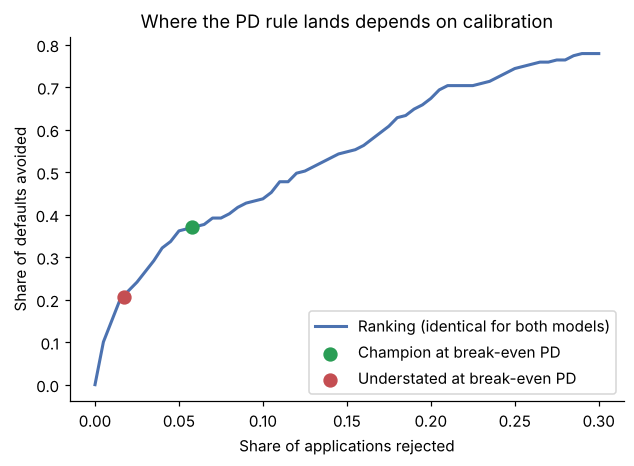

In [12]:
shares = np.linspace(0.0, 0.30, 61)
curve = pd.DataFrame(sv.quantile_cutoff_table(y_test, pd_test, shares))

fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.plot(curve["reject_share"], curve["defaults_avoided"], lw=2, color="#4c72b0", label="Ranking (identical for both models)")
for name, rule, colour in [
    ("Champion at break-even PD", rules["Champion, reject PD > break-even"], "#2a9d55"),
    ("Understated at break-even PD", rules["Understated, reject PD > break-even"], "#c44e52"),
]:
    ax.scatter(rule["reject_share"], rule["defaults_avoided"], s=70, zorder=3, color=colour, label=name)
ax.set(xlabel="Share of applications rejected", ylabel="Share of defaults avoided", title="Where the PD rule lands depends on calibration")
ax.legend(loc="lower right")
fig.savefig(IMG / "cutoffs.png", bbox_inches="tight")

* Both versions rank applicants identically, so they sit on the **same curve**. Only the point where the PD rule lands differs.
* For the calibrated **champion** (class A) the break-even PD comes from economics alone, without looking at outcomes, and lands close to the threshold the back-test finds most profitable.
* With **understated PDs** the same rule rejects far fewer applications and lets through defaults the ranking could have stopped. A **quantile rule** on the same model reproduces the champion's outcome exactly — it uses only the ranking, which is still sound. This is why models whose PDs cannot be trusted are restricted to quantile cut-offs.

## Conclusions

* On portfolios with a few percent of defaults, report **PR-AUC as a multiple of the bad rate** next to ROC-AUC; ROC-AUC alone can approve a model that misses most defaults.
* Discrimination and calibration are different questions. A model can keep its ROC-AUC and PR-AUC and still produce PDs that cannot be used for cut-offs, provisioning or capital.
* The two-step classification (vetoes, then penalties) turns these checks into a reproducible verdict and ties each class to what the model may be used for.

**Using your own data:** replace the synthetic samples with any table that has a 0/1 default flag and predicted PDs, then call `sv.validate(y, pd, reference_pd=pd_on_development_sample)`. Thresholds are configurable through `sv.Thresholds`.